# 1. Dataset Preparation:
## (a) Label Aggregation
### Per-annotator binarize at overlap > 0.5, then majority vote across annotators


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


from pathlib import Path
import json

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'config.json').is_file() and (p / 'data').is_dir():
            return p
    raise RuntimeError("project root (config.json + data/) not found above cwd")

ROOT = find_root()
with open(ROOT / 'config.json') as f:
    CONFIG = json.load(f)
P = CONFIG['paths']

FEATURES_DIR = ROOT / P['orig_npz']
METADATA_CSV = ROOT / P['metadata_csv']
CACHE_DIR    = ROOT / P['strategy_a_artifacts']
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# ── Aggregation hyperparameters ──
OVERLAP_THRESHOLD = 0.5    # per-annotator binarization threshold
                           # an annotator marks class C present if overlap > 0.5

# ── Split ratios ──
TRAIN_RATIO = 0.60
VAL_RATIO   = 0.20
TEST_RATIO  = 0.20
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

print("Todo bien!")

Todo bien!


In [16]:
# ── 1.1 Load metadata.csv ──
metadata = pd.read_csv(METADATA_CSV)
print(f"metadata.csv: {len(metadata)} rows, columns: {list(metadata.columns)}")

# ── 1.2 Build a quick lookup: filename (stem) → collector_id ──
# filenames in metadata.csv may include extension (e.g., '000001.wav') — strip it
metadata["file_id"] = metadata["filename"].str.replace(r"\.[^.]+$", "", regex=True)
file_to_collector = dict(zip(metadata["file_id"], metadata["collector_id"]))
print(f"Unique collectors: {metadata['collector_id'].nunique()}")
print(f"Files per collector — top 5: {metadata['collector_id'].value_counts().head().to_dict()}")

# ── 1.3 Iterate over all npz files ──
npz_files = sorted(FEATURES_DIR.glob("*.npz"))
print(f"\nFound {len(npz_files)} npz files.")

records = []     # one entry per file
for npz_path in npz_files:
    file_id = npz_path.stem
    data = dict(np.load(npz_path, allow_pickle=True))
    records.append({
        "file_id":       file_id,
        "collector_id":  file_to_collector.get(file_id, "UNKNOWN"),
        "annotations":   data["annotations"],          # [T, C, A]
        "class_names":   list(data["class_names"]),
        "annotator_ids": list(data["annotator_ids"]),
        "T":             data["annotations"].shape[0],
        "data":          data,                         # keep full dict for feature extraction later
    })

# ── 1.4 Sanity checks ──
assert all(r["class_names"] == records[0]["class_names"] for r in records), "class_names not consistent"
CLASS_NAMES = records[0]["class_names"]
NUM_CLASSES = len(CLASS_NAMES)

n_unknown = sum(r["collector_id"] == "UNKNOWN" for r in records)
print(f"\nClasses (C={NUM_CLASSES}): {CLASS_NAMES}")
print(f"Files with no collector mapping: {n_unknown}")
print(f"Total segments across all files: {sum(r['T'] for r in records):,}")

metadata.csv: 3656 rows, columns: ['filename', 'target_classes', 'recording_device', 'device_placement', 'recording_environment', 'scene_description', 'license', 'collector_id', 'non_target_classes']
Unique collectors: 408
Files per collector — top 5: {'04d6c4738cd1814c': 10, '23f33a22e31d3072': 10, '0ada14bcb30cabc5': 10, '6281505830f11d19': 10, 'a40d578fc3f26400': 10}

Found 3656 npz files.

Classes (C=15): ['bell_ringing', 'coffee_machine', 'cutlery_dishes', 'door_open_close', 'footsteps', 'keyboard_typing', 'keychain', 'light_switch', 'microwave', 'phone_ringing', 'running_water', 'toilet_flushing', 'vacuum_cleaner', 'wardrobe_drawer_open_close', 'window_open_close']
Files with no collector mapping: 0
Total segments across all files: 168,239


In [19]:
# Refinement 
# ── Diagnostic: how many annotators per file? ──
A_per_file = [r["annotations"].shape[2] for r in records]
A_counts = Counter(A_per_file)
print("Annotator count distribution across files:")
for a, n in sorted(A_counts.items()):
    print(f"  A = {a}:  {n:5d} files  ({n/len(records):.1%})")
print(f"\nMost common: A = {A_counts.most_common(1)[0][0]}")

Annotator count distribution across files:
  A = 1:    625 files  (17.1%)
  A = 2:   1750 files  (47.9%)
  A = 3:   1235 files  (33.8%)
  A = 4:     45 files  (1.2%)
  A = 5:      1 files  (0.0%)

Most common: A = 2


#### Label Aggregation: [T, C, A] → [T, C]
##### We use per-annotator binarization + majority vote across annotators.

In [20]:
def aggregate_labels(annotations: np.ndarray,
                     overlap_threshold: float = 0.5) -> np.ndarray:
    """
    Convert [T, C, A] proportional-overlap annotations into [T, C] binary labels.

    Strategy:
      1) Per-annotator binarization:    a_present = annotation > overlap_threshold
         (annotator marks class present if overlap covers > 50% of segment)
      2) Majority vote across annotators:
         label = 1  iff  more than A/2 annotators marked it present
                         (i.e. strict majority; ties go to 0)

    Returns: int8 array of shape [T, C].
    """
    # Step 1: per-annotator binarization → [T, C, A] of {0, 1}
    bin_per_annotator = (annotations > overlap_threshold).astype(np.int8)

    # Step 2: count agreeing annotators per (segment, class) → [T, C]
    n_annotators = bin_per_annotator.shape[2]
    agree_count  = bin_per_annotator.sum(axis=2)

    # Strict majority: > half (not >=) → ties go to 0
    labels = (agree_count > n_annotators / 2).astype(np.int8)
    return labels


# Apply to every file
for r in records:
    r["labels"] = aggregate_labels(r["annotations"], overlap_threshold=OVERLAP_THRESHOLD)

# Quick sanity check on the first file
ex = records[0]
print(f"File {ex['file_id']}: annotations {ex['annotations'].shape} → labels {ex['labels'].shape}")
print(f"Annotator count for this file: A = {ex['annotations'].shape[2]}")
print(f"Active labels in this file (sum over T,C): {ex['labels'].sum()}")

File 000001: annotations (61, 15, 2) → labels (61, 15)
Annotator count for this file: A = 2
Active labels in this file (sum over T,C): 61


 ### Inspect aggregated label characteristics

In [21]:
# Concatenate all labels into one array [N_total_segments, C]
Y_all = np.concatenate([r["labels"] for r in records], axis=0)
print(f"Total label tensor shape: {Y_all.shape}")

# ── Per-class positive rate (prior) ──
positive_counts = Y_all.sum(axis=0)
positive_rates  = positive_counts / Y_all.shape[0]

label_stats = pd.DataFrame({
    "class": CLASS_NAMES,
    "positive_count": positive_counts,
    "positive_rate":  positive_rates.round(4),
}).sort_values("positive_count", ascending=False).reset_index(drop=True)

print("\n=== Per-class label statistics ===")
print(label_stats.to_string(index=False))

# ── How many segments have NO active class (silence / background)? ──
n_silent  = (Y_all.sum(axis=1) == 0).sum()
n_single  = (Y_all.sum(axis=1) == 1).sum()
n_multi   = (Y_all.sum(axis=1) >= 2).sum()
print(f"\nSegments with 0 active classes: {n_silent:,} ({n_silent/Y_all.shape[0]:.1%})")
print(f"Segments with 1 active class:   {n_single:,} ({n_single/Y_all.shape[0]:.1%})")
print(f"Segments with ≥2 active classes:{n_multi:,} ({n_multi/Y_all.shape[0]:.1%})")

Total label tensor shape: (168239, 15)

=== Per-class label statistics ===
                     class  positive_count  positive_rate
             running_water           21187         0.1259
                 footsteps           19722         0.1172
           keyboard_typing           15563         0.0925
                 microwave           11655         0.0693
            vacuum_cleaner           10835         0.0644
             phone_ringing           10471         0.0622
            cutlery_dishes            9912         0.0589
                  keychain            7597         0.0452
            coffee_machine            6097         0.0362
           door_open_close            5832         0.0347
           toilet_flushing            5213         0.0310
wardrobe_drawer_open_close            3168         0.0188
         window_open_close            2110         0.0125
              bell_ringing            2054         0.0122
              light_switch             501         0.00

rare classes like light_switch have very low positive rate, while footsteps/running_water dominate. Many segments will be completely silent (all zeros) — our classifier has to learn that "no class is active" is a valid output.

In [22]:
# ── Define which feature keys to concatenate ──
# This list keeps ALL 960 features. You can prune later for speed.
FEATURE_KEYS = [
    "zcr_mean",       "zcr_std",       "zcr_min",       "zcr_max",
    "melspect_mean",  "melspect_std",  "melspect_min",  "melspect_max",
    "mfcc_mean",      "mfcc_std",      "mfcc_min",      "mfcc_max",
    "mfcc_d_mean",    "mfcc_d_std",    "mfcc_d_min",    "mfcc_d_max",
    "mfcc_d2_mean",   "mfcc_d2_std",   "mfcc_d2_min",   "mfcc_d2_max",
    "flux_mean",      "flux_std",      "flux_min",      "flux_max",
    "flatness_mean",  "flatness_std",  "flatness_min",  "flatness_max",
    "centroid_mean",  "centroid_std",  "centroid_min",  "centroid_max",
    "bandwidth_mean", "bandwidth_std", "bandwidth_min", "bandwidth_max",
    "contrast_mean",  "contrast_std",  "contrast_min",  "contrast_max",
    "rolloff_low_mean","rolloff_low_std","rolloff_low_min","rolloff_low_max",
    "rolloff_high_mean","rolloff_high_std","rolloff_high_min","rolloff_high_max",
    "energy_mean",    "energy_std",    "energy_min",    "energy_max",
    "power_mean",     "power_std",     "power_min",     "power_max",
]

def build_feature_matrix(file_record, feature_keys):
    """Concatenate all feature arrays for one file along the feature axis → [T, D]."""
    feats = []
    for k in feature_keys:
        arr = file_record["data"][k]
        if arr.ndim == 1:
            arr = arr[:, None]            # promote [T] → [T, 1]
        feats.append(arr.astype(np.float32))
    return np.concatenate(feats, axis=1)  # [T, D]

# Build per-file feature matrices
for r in records:
    r["X"] = build_feature_matrix(r, FEATURE_KEYS)

D = records[0]["X"].shape[1]
print(f"Feature dimensionality D = {D}")        # expect 960
print(f"Example shape: {records[0]['X'].shape}")

# ── Concatenate everything into global arrays ──
X_all          = np.concatenate([r["X"]      for r in records], axis=0)         # [N, D]
Y_all          = np.concatenate([r["labels"] for r in records], axis=0)         # [N, C]
file_id_all    = np.concatenate([np.array([r["file_id"]]      * r["T"]) for r in records])
collector_all  = np.concatenate([np.array([r["collector_id"]] * r["T"]) for r in records])

print(f"\nGlobal X shape: {X_all.shape}  (~{X_all.nbytes/1e6:.0f} MB at float32)")
print(f"Global Y shape: {Y_all.shape}")
print(f"file_id_all:   {file_id_all.shape}, e.g. {file_id_all[:3]}")
print(f"collector_all: {collector_all.shape}, e.g. {collector_all[:3]}")

# ── Free the per-file feature copies to save memory ──
for r in records:
    del r["X"], r["data"]

Feature dimensionality D = 960
Example shape: (61, 960)

Global X shape: (168239, 960)  (~646 MB at float32)
Global Y shape: (168239, 15)
file_id_all:   (168239,), e.g. ['000001' '000001' '000001']
collector_all: (168239,), e.g. ['76646d67ad918592' '76646d67ad918592' '76646d67ad918592']


In [23]:
def two_stage_group_split(groups, train_ratio, val_ratio, test_ratio, seed):
    """
    Returns (train_idx, val_idx, test_idx) over the full [0, N) range,
    where the split is performed at the GROUP level (no group appears in two splits).
    """
    n = len(groups)
    idx = np.arange(n)

    # Stage 1: split off test set
    gss_test = GroupShuffleSplit(n_splits=1, test_size=test_ratio, random_state=seed)
    trainval_idx, test_idx = next(gss_test.split(idx, groups=groups))

    # Stage 2: split remaining into train/val
    rel_val_ratio = val_ratio / (train_ratio + val_ratio)
    gss_val = GroupShuffleSplit(n_splits=1, test_size=rel_val_ratio, random_state=seed)
    sub_train, sub_val = next(gss_val.split(trainval_idx, groups=groups[trainval_idx]))

    train_idx = trainval_idx[sub_train]
    val_idx   = trainval_idx[sub_val]
    return train_idx, val_idx, test_idx


def class_distribution(Y):
    """Return per-class positive rate for a label matrix."""
    return Y.mean(axis=0)


def kl_divergence(p, q, eps=1e-9):
    """Symmetric KL between two prior vectors (used as a balance score)."""
    p = np.clip(p, eps, 1)
    q = np.clip(q, eps, 1)
    return 0.5 * (np.sum(p * np.log(p / q)) + np.sum(q * np.log(q / p)))


# ── Search across seeds for the most balanced split ──
candidate_seeds = list(range(20))
best = {"score": np.inf}

for seed in candidate_seeds:
    tr, va, te = two_stage_group_split(collector_all, TRAIN_RATIO, VAL_RATIO, TEST_RATIO, seed)
    p_tr = class_distribution(Y_all[tr])
    p_va = class_distribution(Y_all[va])
    p_te = class_distribution(Y_all[te])
    # imbalance penalty: total KL between train and the other two
    score = kl_divergence(p_tr, p_va) + kl_divergence(p_tr, p_te)
    if score < best["score"]:
        best = {"score": score, "seed": seed,
                "train_idx": tr, "val_idx": va, "test_idx": te}

print(f"Best seed: {best['seed']}  (KL imbalance score: {best['score']:.4f})")
train_idx, val_idx, test_idx = best["train_idx"], best["val_idx"], best["test_idx"]

# ── Verify the leakage guarantee ──
train_collectors = set(collector_all[train_idx])
val_collectors   = set(collector_all[val_idx])
test_collectors  = set(collector_all[test_idx])

print(f"\nCollectors in train: {len(train_collectors)}")
print(f"Collectors in val:   {len(val_collectors)}")
print(f"Collectors in test:  {len(test_collectors)}")
print(f"Train ∩ Val:  {len(train_collectors & val_collectors)}    (must be 0)")
print(f"Train ∩ Test: {len(train_collectors & test_collectors)}   (must be 0)")
print(f"Val   ∩ Test: {len(val_collectors & test_collectors)}     (must be 0)")

print(f"\nSegment counts: train={len(train_idx):,}  val={len(val_idx):,}  test={len(test_idx):,}")
print(f"Proportion:      train={len(train_idx)/len(Y_all):.2%}  "
      f"val={len(val_idx)/len(Y_all):.2%}  test={len(test_idx)/len(Y_all):.2%}")

Best seed: 9  (KL imbalance score: 0.0054)

Collectors in train: 244
Collectors in val:   82
Collectors in test:  82
Train ∩ Val:  0    (must be 0)
Train ∩ Test: 0   (must be 0)
Val   ∩ Test: 0     (must be 0)

Segment counts: train=100,166  val=34,245  test=33,828
Proportion:      train=59.54%  val=20.35%  test=20.11%


#### - Group split (not stratified split): the unit of independence is the collector, not the segment. Two consecutive segments in the same recording are nearly identical acoustically — a stratified random split would put them in different sets and inflate scores by 10-20%.
#### - Two-stage split: GroupShuffleSplit natively produces 2 splits; we apply it twice to get 3. Seed search: with multilabel data, true stratified group splitting is an open problem (no scikit-learn primitive exists). Searching seeds is a pragmatic workaround that picks the seed where the per-class priors of train/val/test are most similar (measured by symmetric KL divergence).
#### - Why proportions can drift slightly from 60/20/20: collectors contribute different numbers of segments. If you assign a "big" collector to test, test grows in segment count even though collector count is fixed.

## Visualize class distribution across splits

=== Per-class positive rate per split ===
                            train    val   test
class                                          
bell_ringing                 1.09   1.40   1.43
coffee_machine               3.78   3.13   3.65
cutlery_dishes               6.03   5.34   6.05
door_open_close              3.57   3.44   3.18
footsteps                   11.41  11.78  12.58
keyboard_typing              9.11   9.07   9.85
keychain                     4.56   4.53   4.36
light_switch                 0.27   0.41   0.26
microwave                    6.81   6.58   7.62
phone_ringing                6.26   6.20   6.14
running_water               12.82  12.12  12.39
toilet_flushing              3.16   2.82   3.18
vacuum_cleaner               6.39   7.13   5.89
wardrobe_drawer_open_close   1.98   1.79   1.68
window_open_close            1.29   1.23   1.16


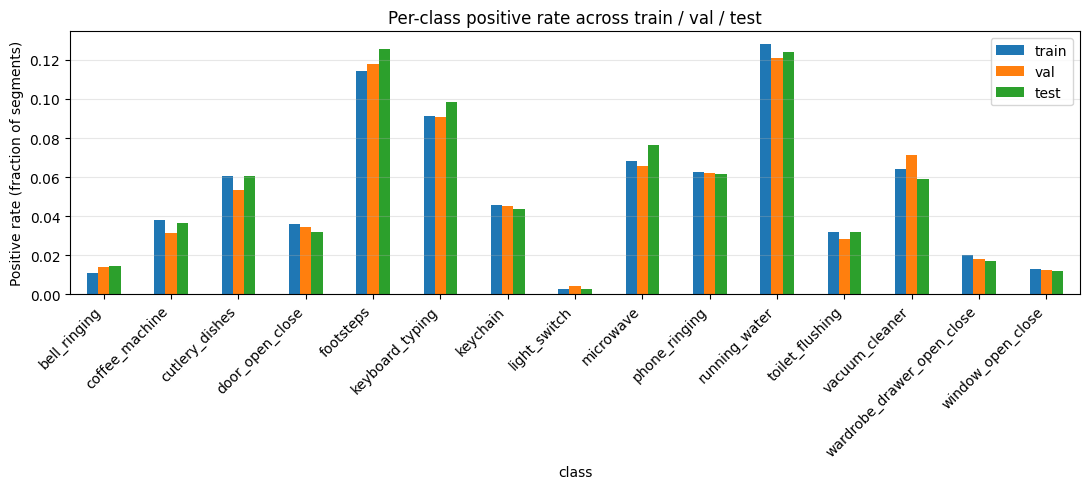

In [24]:
p_tr = class_distribution(Y_all[train_idx])
p_va = class_distribution(Y_all[val_idx])
p_te = class_distribution(Y_all[test_idx])

dist_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": p_tr,
    "val":   p_va,
    "test":  p_te,
}).set_index("class")

print("=== Per-class positive rate per split ===")
print((dist_df * 100).round(2).to_string())

# ── Bar chart for the report ──
fig, ax = plt.subplots(figsize=(11, 5))
dist_df.plot(kind="bar", ax=ax)
ax.set_ylabel("Positive rate (fraction of segments)")
ax.set_title("Per-class positive rate across train / val / test")
ax.set_xticklabels(dist_df.index, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Preprocessing: StandardScaler fit on train only

In [26]:
# ── 7.1  Build a column-index map from FEATURE_KEYS without needing the npz dict ──
# Hardcoded base-name dimensionalities (from the dataset spec / exploration phase):
BASE_DIMS = {
    "zcr": 1, "melspect": 128, "mfcc": 32, "mfcc_d": 32, "mfcc_d2": 32,
    "flux": 1, "flatness": 1, "centroid": 1, "bandwidth": 1, "contrast": 7,
    "rolloff_low": 1, "rolloff_high": 1, "energy": 1, "power": 1,
}

heavy_tailed_groups = ["energy", "power"]   # base names to log-compress

log_mask = np.zeros(D, dtype=bool)
col = 0
for k in FEATURE_KEYS:
    base = k.rsplit("_", 1)[0]              # "power_max" → "power"; "mfcc_d_mean" → "mfcc_d"
    arr_dim = BASE_DIMS[base]
    if base in heavy_tailed_groups:
        log_mask[col:col + arr_dim] = True
    col += arr_dim
assert col == D, f"Column accounting mismatch: {col} != {D}"
print(f"Log-transforming {log_mask.sum()} columns (energy/power); D = {D}.")

Log-transforming 8 columns (energy/power); D = 960.


In [27]:
# ── 7.2  Apply log1p to heavy-tailed features (elementwise — cannot leak) ──
X_all_log = X_all.copy()
X_all_log[:, log_mask] = np.log1p(np.clip(X_all_log[:, log_mask], 0, None))

# Show the effect of log1p on the affected columns only
hi_before = X_all[:, log_mask]
hi_after  = X_all_log[:, log_mask]
print(f"Heavy-tailed cols BEFORE log1p:  min={hi_before.min():.2f}  "
      f"max={hi_before.max():.2f}  mean={hi_before.mean():.2f}")
print(f"Heavy-tailed cols AFTER  log1p:  min={hi_after.min():.2f}  "
      f"max={hi_after.max():.2f}  mean={hi_after.mean():.2f}")

Heavy-tailed cols BEFORE log1p:  min=0.00  max=67940.88  mean=111.97
Heavy-tailed cols AFTER  log1p:  min=0.00  max=11.13  mean=2.53


In [28]:
# ── 7.3  Re-slice with existing split indices ──
X_train = X_all_log[train_idx]
X_val   = X_all_log[val_idx]
X_test  = X_all_log[test_idx]
Y_train, Y_val, Y_test = Y_all[train_idx], Y_all[val_idx], Y_all[test_idx]

# ── 7.4  Fit StandardScaler on TRAIN ONLY ──
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

print(f"\nPre-scaling   X_train:   min={X_train.min():.2f}  max={X_train.max():.2f}  "
      f"mean={X_train.mean():.2f}  std={X_train.std():.2f}")
print(f"Post-scaling  X_train:   min={X_train_scaled.min():.2f}  max={X_train_scaled.max():.2f}  "
      f"mean={X_train_scaled.mean():.4f}  std={X_train_scaled.std():.4f}")

# Per-column post-scaling extremes
col_max_abs = np.abs(X_train_scaled).max(axis=0)
print(f"Per-column |z| max — median: {np.median(col_max_abs):.2f}, "
      f"95th percentile: {np.percentile(col_max_abs, 95):.2f}, "
      f"max: {col_max_abs.max():.2f}")

near_const = np.where(scaler.scale_ < 1e-8)[0]
print(f"Near-constant features (zero variance on train): {len(near_const)}")


Pre-scaling   X_train:   min=-130.25  max=7937.50  mean=36.52  std=369.11
Post-scaling  X_train:   min=-18.49  max=21.77  mean=-0.0000  std=1.0000
Per-column |z| max — median: 6.90, 95th percentile: 14.26, max: 21.77
Near-constant features (zero variance on train): 0


## Save splits to disk for reuse

In [29]:
np.savez_compressed(
    CACHE_DIR / "splits.npz",
    X_train=X_train_scaled.astype(np.float32),
    X_val  =X_val_scaled.astype(np.float32),
    X_test =X_test_scaled.astype(np.float32),
    Y_train=Y_train.astype(np.int8),
    Y_val  =Y_val.astype(np.int8),
    Y_test =Y_test.astype(np.int8),
    feature_names=np.array(FEATURE_KEYS),
    class_names  =np.array(CLASS_NAMES),
    train_idx=train_idx, val_idx=val_idx, test_idx=test_idx,
    scaler_mean =scaler.mean_,
    scaler_scale=scaler.scale_,
)
print(f"Saved to {CACHE_DIR/'splits.npz'}")
print("Subsequent notebooks can load with: np.load('strategy_A_baseline/artifacts/splits.npz')")

Saved to cache_classification/splits.npz
Subsequent notebooks can load with: np.load('cache_classification/splits.npz')
